# Conversion Rate - Statistical Analysis

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.cloud import bigquery

## 2. BigQuery Connection

In [2]:
# Connect to BigQuery using local Google Cloud credentials.
client = bigquery.Client(project="ga4-conversion-analytics")

# Execute a test query.
query = "SELECT 1 AS connection_ok"
result = client.query(query).result()

# Retrieve the first row from the query results.
row = next(iter(result))

print(f"BigQuery connection: {row.connection_ok}")

BigQuery connection: 1


## 3. Session Data

In [3]:
from pathlib import Path

# Access the SQL file in the sibling directory.
sql_path = Path("../sql/06_statistical_export.sql")

# Read and execute the SQL query.
query = sql_path.read_text(encoding="utf-8")
df = client.query(query).result().to_dataframe(create_bqstorage_client=False)

# Check the loaded data.
print(df.shape)
print(df["device_category"].value_counts(dropna=False))

(360129, 9)
device_category
desktop    208942
mobile     143185
tablet       8002
Name: count, dtype: int64


### 3.1 Data Validation

In [4]:
# Check whether each row represents a unique session
unique_sessions = df[["user_pseudo_id", "ga_session_id"]].drop_duplicates().shape[0]

# Check missing values across all columns
missing_values = df.isna().sum()

# Summarize the dataset
print(f"Total sessions: {len(df):,}")
print(f"Unique sessions: {unique_sessions:,}")
print(f"Purchase sessions: {df['has_purchase'].sum():,}")
print(f"Date range: {df['session_date'].min()} to {df['session_date'].max()}")
print("\nMissing values:")
print(missing_values)

Total sessions: 360,129
Unique sessions: 360,129
Purchase sessions: 4,848
Date range: 2020-11-01 to 2021-01-31

Missing values:
user_pseudo_id         0
ga_session_id          0
session_date           0
session_timestamp      0
device_category        0
has_search             0
has_promotion_view     0
has_promotion_click    0
has_purchase           0
dtype: int64


## 4. Search vs. No Search

In [5]:
# Aggregate sessions and purchases by search activity.
search_summary = (df.groupby("has_search")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
    .reset_index()
)

# Calculate session conversion rates.
search_summary["conversion_rate_pct"] = (100 * search_summary["purchase_sessions"] / search_summary["total_sessions"]).round(2)

# Assign readable segment names.
search_summary["segment"] = search_summary["has_search"].map({True: "Search", False: "No Search"})

# Display the comparison.
display(search_summary[["segment", "total_sessions", "purchase_sessions", "conversion_rate_pct"]])

,segment,total_sessions,purchase_sessions,conversion_rate_pct
0,No Search,344410,4197,1.22
1,Search,15719,651,4.14


### 4.1 Statistical Significance

In [6]:
import statsmodels.api as sm

# Linear Probability Model (LPM) estimated using Ordinary Least Squares (OLS) with Cluster-Robust Standard Errors (CRSE) clustered at the user level.

# Prepare the binary predictor and purchase outcome.
X = sm.add_constant(df["has_search"].astype(int))
y = df["has_purchase"].astype(int)

# Estimate the conversion-rate difference with user-clustered standard errors.
model = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": df["user_pseudo_id"]})

# Extract the difference, confidence interval, and p-value.
difference_pp = model.params["has_search"] * 100
ci_lower, ci_upper = model.conf_int().loc["has_search"] * 100
p_value = model.pvalues["has_search"]

print(f"Conversion rate difference: {difference_pp:.2f} pp")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}] pp")
print(f"p-value: {p_value:.5f}")

Conversion rate difference: 2.92 pp
95% CI: [2.60, 3.24] pp
p-value: 0.00000


> The result has business significance. Sessions that include product searches have a conversion rate approximately 3.4 times higher.


### 4.2 Conversion Rate Comparison

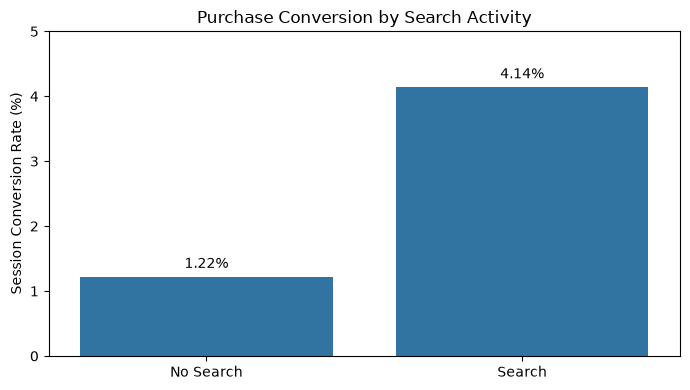

In [21]:
# Compare observed conversion rates across search segments.
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=search_summary,
    x="segment",
    y="conversion_rate_pct",
    order=["No Search", "Search"],
    errorbar=None,
    ax=ax
)

# Display conversion rates above the bars.
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

# Add space above the bars for value labels.
ax.set_ylim(0, 5)

ax.set(
    title="Purchase Conversion by Search Activity",
    xlabel="",
    ylabel="Session Conversion Rate (%)"
)

plt.tight_layout()
plt.show()

## 5. Device Conversion Analysis

In [8]:
# Aggregate sessions and purchases by device category.
device_summary = (
    df.groupby("device_category")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
    .reset_index()
)

# Calculate session conversion rates.
device_summary["conversion_rate_pct"] = (100 * device_summary["purchase_sessions"] / device_summary["total_sessions"]).round(2)

# Sort devices in a consistent order.
device_order = ["desktop", "mobile", "tablet"]

device_summary["device_category"] = pd.Categorical(
    device_summary["device_category"],
    categories=device_order,
    ordered=True
)

device_summary = device_summary.sort_values("device_category")

display(device_summary)

,device_category,total_sessions,purchase_sessions,conversion_rate_pct
0,desktop,208942,2749,1.32
1,mobile,143185,1995,1.39
2,tablet,8002,104,1.3


### 5.1 Statistical Significance

In [9]:
# Linear Probability Model (OLS) with Cluster-Robust Standard Errors
# Wald test
# H₀: the conversion rates for desktop, mobile, and tablet are equal.
# H₁: at least one conversion rate is different.

# Use desktop as the reference category.
device_dummies = pd.get_dummies(df["device_category"], dtype=int)[["mobile", "tablet"]]

X_device = sm.add_constant(device_dummies)
y_device = df["has_purchase"].astype(int)

# Fit a linear probability model with user-clustered standard errors.
device_model = sm.OLS(y_device, X_device).fit(cov_type="cluster", cov_kwds={"groups": df["user_pseudo_id"]})

# Test whether conversion rates are equal across all three devices.
wald_result = device_model.wald_test("mobile = 0, tablet = 0", scalar=True)

print(f"Wald chi-square: {wald_result.statistic:.3f}")
print(f"p-value: {wald_result.pvalue:.4g}")

Wald chi-square: 3.595
p-value: 0.1657


> do not reject the null hypothesis of equal conversion rates for desktop, mobile, and tablet.

## 6. Cluster Structure

In [10]:
# Count sessions associated with each user.
sessions_per_user = df.groupby("user_pseudo_id").size()

# Check the number and size of user-level clusters.
print(f"Unique users: {len(sessions_per_user):,}")
print(f"Median sessions per user: {sessions_per_user.median():.0f}")
print(f"Maximum sessions per user: {sessions_per_user.max():,}")
print(f"Users with multiple sessions: {(sessions_per_user.gt(1).mean() * 100):.2f}%")

Unique users: 270,154
Median sessions per user: 1
Maximum sessions per user: 12
Users with multiple sessions: 17.53%


## 7. Promotion Engagement

In [12]:
# Restrict the analysis to the period with more complete event tracking.
df_promo = df.loc[pd.to_datetime(df["session_date"]) >= "2020-11-25"].copy()

# Assign each session to one mutually exclusive promotion segment.
df_promo["promotion_segment"] = np.select([df_promo["has_promotion_click"].to_numpy(dtype=bool), df_promo["has_promotion_view"].to_numpy(dtype=bool)],
    ["Promotion Click", "Promotion View Only"], default="No Recorded Promotion Interaction")

# Calculate purchase conversion rates for each segment.
promo_summary = (
    df_promo.groupby("promotion_segment")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
)

promo_summary["conversion_rate_pct"] = (100 * promo_summary["purchase_sessions"] / promo_summary["total_sessions"]).round(2)

# Display segments in a consistent order.
promo_summary = promo_summary.reindex(["Promotion Click", "Promotion View Only", "No Recorded Promotion Interaction"])

display(promo_summary)

,total_sessions,purchase_sessions,conversion_rate_pct
promotion_segment,,,
Promotion Click,6370,240,3.77
Promotion View Only,86943,2997,3.45
No Recorded Promotion Interaction,182396,473,0.26


### 7.1 Statistical Significance

In [13]:
# Use sessions without recorded promotion interactions as the reference group.
X_promo = pd.get_dummies(df_promo["promotion_segment"], dtype=int)[["Promotion Click", "Promotion View Only"]]

X_promo.columns = ["click", "view_only"]
X_promo = sm.add_constant(X_promo)

y_promo = df_promo["has_purchase"].astype(int)

# Fit the model with user-clustered robust standard errors.
promo_model = sm.OLS(y_promo, X_promo).fit(cov_type="cluster", cov_kwds={"groups": df_promo["user_pseudo_id"]})

# Test whether conversion rates are equal across all promotion segments.
promo_wald = promo_model.wald_test("click = 0, view_only = 0", scalar=True)

print(f"Wald chi-square: {promo_wald.statistic:.3f}")
print(f"p-value: {promo_wald.pvalue:.5f}")

Wald chi-square: 2627.646
p-value: 0.00000


### 7.2 Promotion Click vs. View Only

In [14]:
# Test the difference between promotion clicks and views without clicks.
contrast = promo_model.t_test("click - view_only = 0")

# Extract the estimated difference and its statistical uncertainty.
difference_pp = contrast.effect.item() * 100
ci_lower, ci_upper = contrast.conf_int()[0] * 100
p_value = contrast.pvalue.item()

print(f"Conversion rate difference: {difference_pp:.2f} pp")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}] pp")
print(f"p-value: {p_value:.5f}")

Conversion rate difference: 0.32 pp
95% CI: [-0.16, 0.80] pp
p-value: 0.19211


### 7.3 Promotion Conversion Comparison

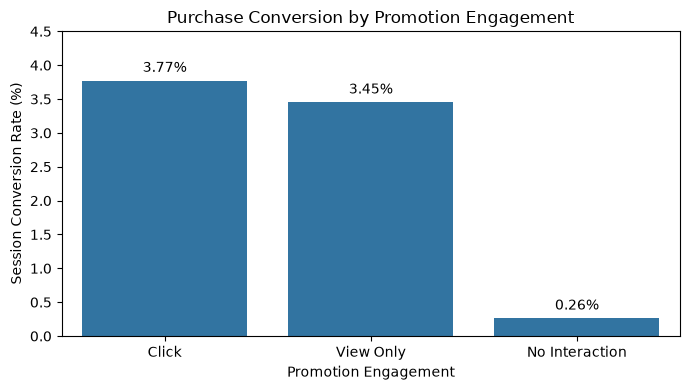

In [18]:
# Prepare promotion conversion rates for visualization.
promo_plot = promo_summary.reset_index().copy()

promo_plot["promotion_segment"] = [
    "Click", "View Only", "No Interaction"
]

# Compare observed session conversion rates.
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=promo_plot,
    x="promotion_segment",
    y="conversion_rate_pct",
    errorbar=None,
    ax=ax
)

# Display conversion rates above the bars.
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

# Add space above the bars for value labels.
ax.set_ylim(0, 4.5)

ax.set(
    title="Purchase Conversion by Promotion Engagement",
    xlabel="Promotion Engagement",
    ylabel="Session Conversion Rate (%)"
)

plt.tight_layout()
plt.show()

## 8. First vs. Subsequent Sessions

In [22]:
# Sort sessions chronologically within each user.
df_visits = df.sort_values(["user_pseudo_id", "session_timestamp", "ga_session_id"]).copy()

# Identify the first observed session for each user.
df_visits["visit_segment"] = np.where(df_visits.groupby("user_pseudo_id").cumcount() == 0,"First Observed Session","Subsequent Session")

# Calculate purchase conversion by visit segment.
visit_summary = (
    df_visits.groupby("visit_segment")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
)

visit_summary["conversion_rate_pct"] = (100 * visit_summary["purchase_sessions"] / visit_summary["total_sessions"]).round(2)

display(visit_summary)

,total_sessions,purchase_sessions,conversion_rate_pct
visit_segment,,,
First Observed Session,270154,2090,0.77
Subsequent Session,89975,2758,3.07


### 8.1 Statistical Significance

In [23]:
# Identify subsequent sessions; first observed sessions are the reference group.
X_visit = sm.add_constant(
    df_visits["visit_segment"]
    .eq("Subsequent Session")
    .astype(int)
    .rename("subsequent")
)

y_visit = df_visits["has_purchase"].astype(int)

# Estimate the conversion-rate difference with user-clustered standard errors.
visit_model = sm.OLS(y_visit, X_visit).fit(cov_type="cluster", cov_kwds={"groups": df_visits["user_pseudo_id"]})

# Extract the estimated difference and its statistical uncertainty.
difference_pp = visit_model.params["subsequent"] * 100
ci_lower, ci_upper = visit_model.conf_int().loc["subsequent"] * 100
p_value = visit_model.pvalues["subsequent"]

print(f"Conversion rate difference: {difference_pp:.2f} pp")
print(f"95% CI: [{ci_lower:.2f}, {ci_upper:.2f}] pp")
print(f"p-value: {p_value:.5f}")

Conversion rate difference: 2.29 pp
95% CI: [2.17, 2.41] pp
p-value: 0.00000


### 8.2 Conversion Rate Comparison

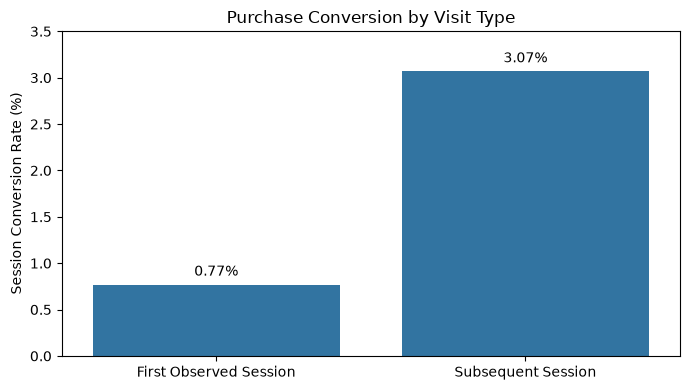

In [26]:
# Prepare conversion rates for visualization.
visit_plot = visit_summary.reset_index()

# Compare first observed and subsequent sessions.
fig, ax = plt.subplots(figsize=(7, 4))

sns.barplot(
    data=visit_plot,
    x="visit_segment",
    y="conversion_rate_pct",
    order=["First Observed Session", "Subsequent Session"],
    errorbar=None,
    ax=ax
)

# Display conversion rates above the bars.
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

ax.set(
    title="Purchase Conversion by Visit Type",
    xlabel="",
    ylabel="Session Conversion Rate (%)"
)

# Add space above the bars for value labels.
ax.set_ylim(0, 3.5)

plt.tight_layout()
plt.show()

### 8.3 Conversion by Session Number

In [27]:
# Number sessions chronologically for each user, starting from 1.
df_visits["session_number"] = (df_visits.groupby("user_pseudo_id").cumcount() + 1)

# Calculate purchase conversion for each session number.
session_number_summary = (
    df_visits.groupby("session_number")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
    .reset_index()
)

# Express conversion rates as percentages.
session_number_summary["conversion_rate_pct"] = (100 * session_number_summary["purchase_sessions"] / session_number_summary["total_sessions"]).round(2)

display(session_number_summary)

,session_number,total_sessions,purchase_sessions,conversion_rate_pct
0,1,270154,2090,0.77
1,2,47364,955,2.02
2,3,17828,654,3.67
3,4,9506,412,4.33
4,5,5683,262,4.61
5,6,3581,172,4.8
6,7,2343,117,4.99
7,8,1552,77,4.96
8,9,983,53,5.39
9,10,632,29,4.59


### 8.4 Conversion Trend by Session Number

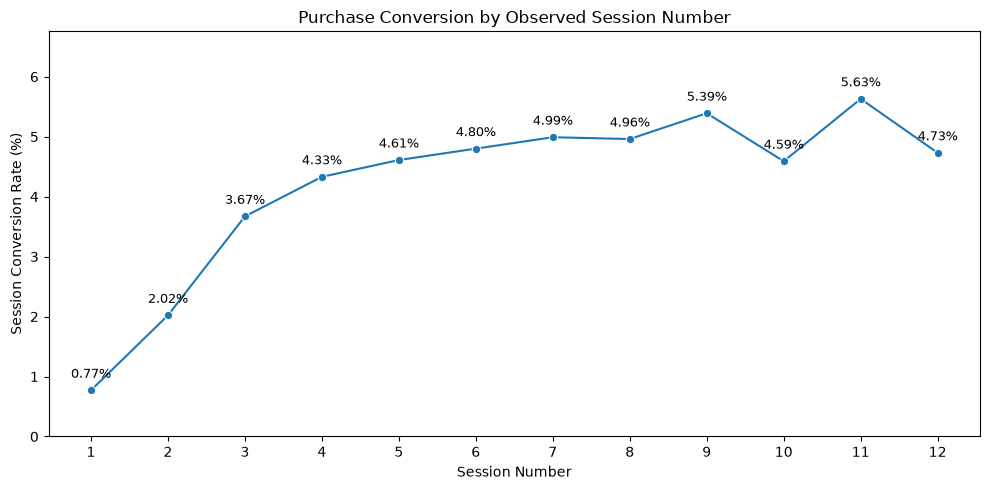

In [28]:
# Visualize conversion rates across consecutive observed sessions.
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=session_number_summary,
    x="session_number",
    y="conversion_rate_pct",
    marker="o",
    errorbar=None,
    ax=ax
)

# Display conversion rates next to the data points.
for row in session_number_summary.itertuples(index=False):
    ax.annotate(
        f"{row.conversion_rate_pct:.2f}%",
        (row.session_number, row.conversion_rate_pct),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set(
    title="Purchase Conversion by Observed Session Number",
    xlabel="Session Number",
    ylabel="Session Conversion Rate (%)"
)

ax.set_xticks(session_number_summary["session_number"])
ax.set_ylim(0, session_number_summary["conversion_rate_pct"].max() * 1.2)

plt.tight_layout()
plt.show()

## 9. Temporal Conversion Analysis

### 9.1 Conversion by Day of Week

In [29]:
# Convert session start timestamps from microseconds to UTC datetime.
df_time = df.copy()

df_time["session_start_utc"] = pd.to_datetime(df_time["session_timestamp"], unit="us", utc=True)

# Extract the weekday of each session start.
df_time["day_of_week"] = df_time["session_start_utc"].dt.day_name()

# Calculate session counts, purchases, and conversion rates.
weekday_summary = (
    df_time.groupby("day_of_week")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
    .reset_index()
)

weekday_summary["conversion_rate_pct"] = (100 * weekday_summary["purchase_sessions"] / weekday_summary["total_sessions"]).round(2)

# Display weekdays in chronological order.
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday_summary["day_of_week"] = pd.Categorical(weekday_summary["day_of_week"], categories=weekday_order, ordered=True)

weekday_summary = weekday_summary.sort_values("day_of_week")

display(weekday_summary)

,day_of_week,total_sessions,purchase_sessions,conversion_rate_pct
1,Monday,51819,720,1.39
5,Tuesday,60697,861,1.42
6,Wednesday,60100,832,1.38
4,Thursday,55762,712,1.28
0,Friday,50936,819,1.61
2,Saturday,40299,519,1.29
3,Sunday,40516,385,0.95


In [33]:
# Use Sunday as the reference category.
weekday_dummies = pd.get_dummies(df_time["day_of_week"], dtype=int)[weekday_order[:-1]]

X_weekday = sm.add_constant(weekday_dummies)
y_weekday = df_time["has_purchase"].astype(int)

# Fit the model with user-clustered standard errors.
weekday_model = sm.OLS(y_weekday, X_weekday).fit(cov_type="cluster", cov_kwds={"groups": df_time["user_pseudo_id"]})

# Test whether all weekday conversion rates are equal.
weekday_wald = weekday_model.wald_test("Monday = 0, Tuesday = 0, Wednesday = 0, " "Thursday = 0, Friday = 0, Saturday = 0", scalar=True)

print(f"Wald chi-square: {weekday_wald.statistic:.3f}")
print(f"p-value: {weekday_wald.pvalue:.5f}")

Wald chi-square: 93.051
p-value: 0.00000


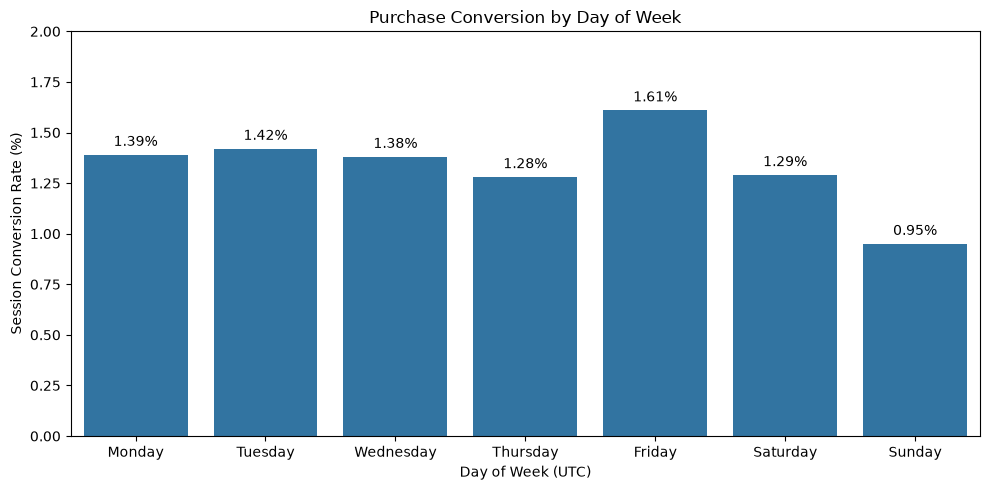

In [35]:
# Compare observed conversion rates across weekdays.
fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=weekday_summary,
    x="day_of_week",
    y="conversion_rate_pct",
    order=weekday_order,
    errorbar=None,
    ax=ax
)

# Display conversion rates above the bars.
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

ax.set(
    title="Purchase Conversion by Day of Week",
    xlabel="Day of Week (UTC)",
    ylabel="Session Conversion Rate (%)"
)

# Add space above the bars for value labels.
ax.set_ylim(0, 2)


plt.tight_layout()
plt.show()

In [44]:
# Compare Friday and Sunday conversion rates.
friday_diff = weekday_model.params["Friday"] * 100
ci_low, ci_high = weekday_model.conf_int().loc["Friday"] * 100
p_value = weekday_model.pvalues["Friday"]

print(f"Conversion rate difference: {friday_diff:.2f} pp")
print(f"95% CI: [{ci_low:.2f}, {ci_high:.2f}] pp")
print(f"p-value: {p_value:.5f}")

Conversion rate difference: 0.66 pp
95% CI: [0.51, 0.80] pp
p-value: 0.00000


### 9.2 Conversion by Hour

In [30]:
# Extract the session start hour in UTC.
df_time["session_hour"] = df_time["session_start_utc"].dt.hour

# Calculate session counts and purchases by hour.
hourly_summary = (
    df_time.groupby("session_hour")["has_purchase"]
    .agg(total_sessions="size", purchase_sessions="sum")
    .reset_index()
)

# Calculate hourly session conversion rates.
hourly_summary["conversion_rate_pct"] = (100 * hourly_summary["purchase_sessions"] / hourly_summary["total_sessions"]).round(2)

display(hourly_summary)

,session_hour,total_sessions,purchase_sessions,conversion_rate_pct
0,0,15032,189,1.26
1,1,15037,196,1.3
2,2,14997,197,1.31
3,3,14970,216,1.44
4,4,14828,197,1.33
5,5,15261,234,1.53
6,6,15059,199,1.32
7,7,14875,206,1.38
8,8,14987,190,1.27
9,9,15247,211,1.38


> an unusually even distribution of activity for an online store.

### 9.3 Timestamp Validation

In [31]:
# Compare UTC timestamp dates with GA4 session dates.
date_difference = (
    df_time["session_start_utc"].dt.tz_localize(None).dt.normalize()
    - pd.to_datetime(df_time["session_date"])
).dt.days

# Display the distribution of date differences.
print(date_difference.value_counts().sort_index())

# Flag discrepancies larger than one day.
print(
    f"\nSessions with date difference > 1 day: "
    f"{(date_difference.abs() > 1).sum():,}"
)

0    360129
Name: count, dtype: int64

Sessions with date difference > 1 day: 0


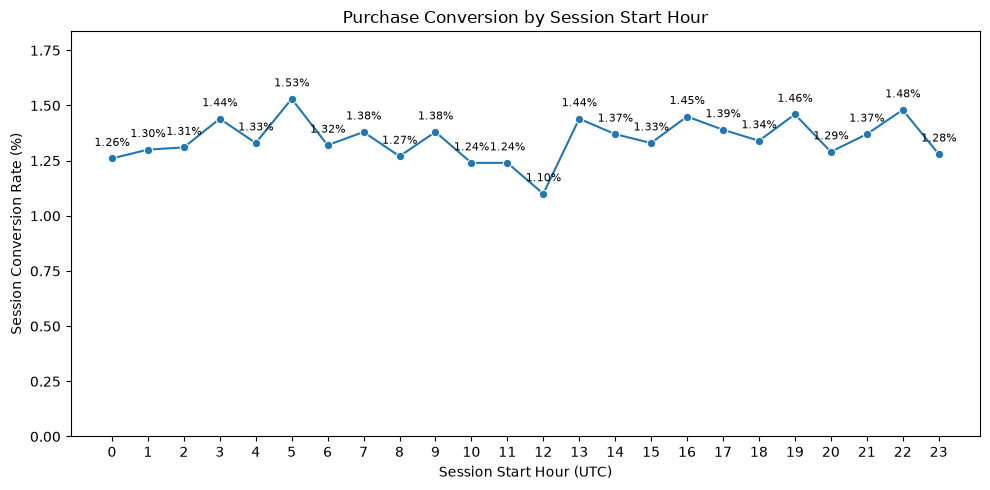

In [37]:
# Visualize session conversion rates by hour of day.
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=hourly_summary,
    x="session_hour",
    y="conversion_rate_pct",
    marker="o",
    errorbar=None,
    ax=ax
)

# Display conversion rates above each data point.
for row in hourly_summary.itertuples(index=False):
    ax.annotate(
        f"{row.conversion_rate_pct:.2f}%",
        (row.session_hour, row.conversion_rate_pct),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

ax.set(
    title="Purchase Conversion by Session Start Hour",
    xlabel="Session Start Hour (UTC)",
    ylabel="Session Conversion Rate (%)"
)

# Display all 24 hours and add space above the highest value.
ax.set_xticks(range(24))
ax.set_ylim(0, hourly_summary["conversion_rate_pct"].max() * 1.2)

plt.tight_layout()
plt.show()

### 9.7 Conversion Heatmap by Day and Hour

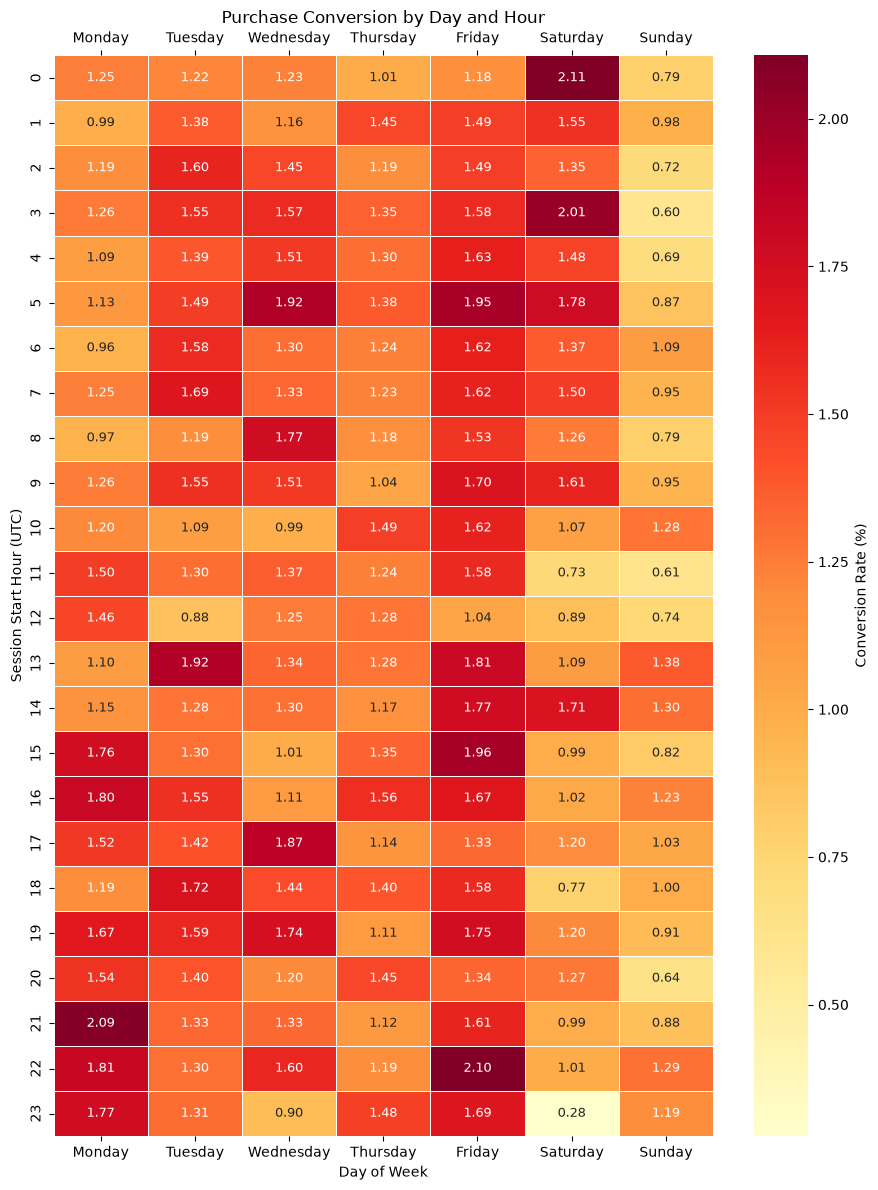

In [43]:
# Calculate conversion rates by hour and weekday.
conversion_heatmap = (
    df_time.groupby(["session_hour", "day_of_week"])["has_purchase"]
    .mean()
    .mul(100)
    .unstack("day_of_week")
    .reindex(columns=weekday_order)
    .astype(float)
)
# Visualize conversion rates as a heatmap.
fig, ax = plt.subplots(figsize=(9, 12))

sns.heatmap(
    conversion_heatmap,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Conversion Rate (%)"},
    annot_kws={"size": 9},
    ax=ax
)

ax.set(
    title="Purchase Conversion by Day and Hour",
    xlabel="Day of Week",
    ylabel="Session Start Hour (UTC)"
)

# Display weekday labels at the top and bottom.
ax.tick_params(
    axis="x",
    top=True,
    bottom=True,
    labeltop=True,
    labelbottom=True
)

ax.tick_params(axis="x", labelrotation=0)

plt.tight_layout()
plt.show()